# NSCG 2023 + O*NET: EDA (issue #20)

Input: `data/nscg2023_onet_clean.csv`, written by `nscg_cleaning.ipynb` (79,800 employed respondents).

This first part profiles data quality and the numeric distributions. Statistics are unweighted unless a column says otherwise.

In [33]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

In [34]:
pd.set_option("display.max_rows", 100)
DATA = Path("../../data")  # notebook runs from notebooks/NSCG/

# Codes are identifiers, not amounts, so read them as text
CODES = ["OBSNUM", "N3OCPR", "INDCODE"]
df = pd.read_csv(DATA / "nscg2023_onet_clean.csv", dtype={c: str for c in CODES}, low_memory=False)

# CSV writes "no missing O*NET codes" as an empty string, which reloads as NaN
df["onet_no_wv"] = df.onet_no_wv.fillna("")

# CSV drops pandas categories; restore them for the labeled columns from cleaning step 5c
CATEGORICAL = ["NEDTP", "RACETHM", "CTZN", "MARSTA", "NDGMEMG", "TELEC", "SEX_2023",
               "ncses_label", "mapping_type", "wv_status"]
df[CATEGORICAL] = df[CATEGORICAL].astype("category")

FACTORS = ["ADV", "BEN", "CHAL", "IND", "LOC", "RESP", "SAL", "SEC", "SOC"]
SAT_COLS = ["SAT" + f for f in FACTORS]
FAC_COLS = ["FAC" + f for f in FACTORS]
VALUES = ["Achievement", "Independence", "Recognition", "Relationships", "Support", "Working Conditions"]

print(df.shape)

(79800, 71)


/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_65334/415609508.py:9: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["onet_no_wv"] = df.onet_no_wv.fillna("")
/var/folders/ny/p5hb2xbx46g25_c_0lg5mhyc0000gn/T/ipykernel_65334/41560

## 1. Completeness and missing values

Completeness is the share of values present; missing % is its complement. Blanks are expected only in the O*NET columns, `INDCODE`, `EARN` and `log_salary` (see cleaning step 8).

In [35]:
missing = df.isna()
print(f"Overall completeness: {(1 - missing.values.mean()) * 100:.2f}% of {missing.size:,} cells")
print(f"Rows with no blanks: {(~missing.any(axis=1)).sum():,} of {len(df):,} "
      f"({(~missing.any(axis=1)).mean() * 100:.1f}%)")
print(f"Columns with no blanks: {(~missing.any()).sum()} of {df.shape[1]}")

completeness = pd.DataFrame(
    {
        "n_missing": missing.sum(),
        "missing_pct": (missing.mean() * 100).round(2),
        "completeness_pct": ((1 - missing.mean()) * 100).round(2),
    }
)
completeness[completeness.n_missing > 0].sort_values("n_missing", ascending=False)

Overall completeness: 99.44% of 5,665,800 cells
Rows with no blanks: 74,054 of 79,800 (92.8%)
Columns with no blanks: 61 of 71


,n_missing,missing_pct,completeness_pct
Achievement,4955,6.21,93.79
Independence,4955,6.21,93.79
Recognition,4955,6.21,93.79
Relationships,4955,6.21,93.79
Support,4955,6.21,93.79
Working Conditions,4955,6.21,93.79
job_zone,886,1.11,98.89
INDCODE,499,0.63,99.37
log_salary,287,0.36,99.64
EARN,99,0.12,99.88


## 2. Duplicate rows

- **Exact duplicates:** rows identical in every column.
- **Duplicate respondents:** repeated `OBSNUM`, the respondent ID.
- **Identical answers:** rows identical apart from `OBSNUM` and the survey weight. A few are plausible by chance with mostly categorical answers; many would suggest a processing error.

In [36]:
answer_cols = df.columns.drop(["OBSNUM", "WTSURVY"])
pd.Series(
    {
        "exact duplicate rows": df.duplicated().sum(),
        "duplicate OBSNUM": df.OBSNUM.duplicated().sum(),
        "identical answers (excl. ID and weight)": df.duplicated(subset=answer_cols).sum(),
    },
    name="count",
)

exact duplicate rows                       0
duplicate OBSNUM                           0
identical answers (excl. ID and weight)    0
Name: count, dtype: int64

## 3. Uniqueness

Distinct values per column. `OBSNUM` should be 100% unique; a column with one distinct value carries no information; and binary or scale columns should have exactly the number of levels their codebook defines.

In [37]:
uniqueness = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "pct_unique": (df.nunique() / len(df) * 100).round(2),
        "top_value": df.mode().iloc[0],
    }
)
print("Constant columns:", uniqueness.index[uniqueness.n_unique <= 1].tolist() or "none")
uniqueness.sort_values("n_unique", ascending=False)

Constant columns: none


,dtype,n_unique,pct_unique,top_value
OBSNUM,object,79800,100.00,2023000002
WTSURVY,float64,78261,98.07,5691.2597
EARN,float64,8429,10.56,100000.0
SALARY,int64,6537,8.19,100000.0
log_salary,float64,6536,8.19,11.512925
INDCODE,object,264,0.33,7870
ncses_label,category,129,0.16,Software developers – applications and systems...
N3OCPR,object,129,0.16,110590
HRSWK,int64,91,0.11,40.0
Working Conditions,float64,75,0.09,4.89913


## 4. Data type validity

Two checks:

1. **Types:** each column has the type its role calls for (text codes, integers for scales, True/False flags, numbers, categories).
2. **Values:** every value falls in the range or format the codebook allows. `n_invalid` counts violations; blanks aren't counted here, since section 1 covers them.

In [38]:
FLAGS = ["salary_zero", "salary_low", "salary_topcoded", "earn_topcoded", "hours_topcoded"]
EXPECTED_KIND = {
    "text code": CODES + ["onet_no_wv"],
    "integer": ["JOBSATIS"] + SAT_COLS + FAC_COLS
    + ["OCEDRLP", "EMSIZE", "TELEFR", "AGE", "SALARY", "HRSWK", "WKSWK",
       "n_soc", "n_onet", "n_onet_with_wv", "n_onet_with_jz", "very_satisfied"],
    "boolean": ["MGRNAT", "MGROTH", "MGRSOC", "JOBINS", "JOBPENS", "JOBPROFT", "JOBVAC", "HISPANIC",
                "partial_substantive", "has_work_values", "has_job_zone"] + FLAGS,
    "float": ["WTSURVY", "EARN", "log_salary", "job_zone"] + VALUES,
    "category": CATEGORICAL,
}
KIND_CHECK = {
    "text code": pd.api.types.is_object_dtype,
    "integer": pd.api.types.is_integer_dtype,
    "boolean": pd.api.types.is_bool_dtype,
    "float": pd.api.types.is_float_dtype,
    "category": lambda s: isinstance(s.dtype, pd.CategoricalDtype),
}

unlisted = set(df.columns) - {c for cols in EXPECTED_KIND.values() for c in cols}
print("Columns without an expected type:", sorted(unlisted) or "none")
type_issues = [
    (col, kind, str(df[col].dtype))
    for kind, cols in EXPECTED_KIND.items()
    for col in cols
    if not KIND_CHECK[kind](df[col])
]
pd.DataFrame(type_issues, columns=["column", "expected", "actual"]) if type_issues else print("All column types as expected")

Columns without an expected type: none
All column types as expected


In [39]:
def outside(cols, lo, hi):
    """Count present values outside [lo, hi] across cols."""
    vals = df[cols] if isinstance(cols, list) else df[[cols]]
    return int(((vals < lo) | (vals > hi)).sum().sum())


def not_matching(col, pattern):
    """Count present values that don't fully match a regex."""
    s = df[col].dropna()
    return int((~s.str.fullmatch(pattern)).sum())


EXPECTED_LEVELS = {"NEDTP": 9, "RACETHM": 7, "CTZN": 4, "MARSTA": 6, "NDGMEMG": 7, "TELEC": 5, "SEX_2023": 2,
                   "ncses_label": 129, "mapping_type": 3, "wv_status": 4}

validity = [
    ("OBSNUM", "10-digit ID", not_matching("OBSNUM", r"\d{10}")),
    ("N3OCPR", "6-digit NCSES code", not_matching("N3OCPR", r"\d{6}")),
    ("INDCODE", "4-digit Census industry code", not_matching("INDCODE", r"\d{4}")),
    ("WTSURVY", "> 0", int((df.WTSURVY <= 0).sum())),
    ("JOBSATIS", "1-4", outside("JOBSATIS", 1, 4)),
    ("SAT* (9 cols)", "1-4", outside(SAT_COLS, 1, 4)),
    ("FAC* (9 cols)", "1-4", outside(FAC_COLS, 1, 4)),
    ("OCEDRLP", "1-3", outside("OCEDRLP", 1, 3)),
    ("EMSIZE", "1-8", outside("EMSIZE", 1, 8)),
    ("TELEFR", "0-4", outside("TELEFR", 0, 4)),
    ("AGE", "18-80", outside("AGE", 18, 80)),
    ("SALARY", ">= 0", int((df.SALARY < 0).sum())),
    ("EARN", ">= 0", int((df.EARN < 0).sum())),
    ("HRSWK", "1-96", outside("HRSWK", 1, 96)),
    ("WKSWK", "1-52", outside("WKSWK", 1, 52)),
    ("Work Values (6 cols)", "1-7 (O*NET extent scale)", outside(VALUES, 1, 7)),
    ("job_zone", "1-5", outside("job_zone", 1, 5)),
    ("very_satisfied", "0 or 1", int((~df.very_satisfied.isin([0, 1])).sum())),
] + [
    (col, f"at most {n} levels, none blank", max(df[col].nunique() - n, 0) + int(df[col].isna().sum()))
    for col, n in EXPECTED_LEVELS.items()
]

pd.DataFrame(validity, columns=["column", "rule", "n_invalid"])

,column,rule,n_invalid
0,OBSNUM,10-digit ID,0
1,N3OCPR,6-digit NCSES code,0
2,INDCODE,4-digit Census industry code,0
3,WTSURVY,> 0,0
4,JOBSATIS,1-4,0
5,SAT* (9 cols),1-4,0
6,FAC* (9 cols),1-4,0
7,OCEDRLP,1-3,0
8,EMSIZE,1-8,0
9,TELEFR,0-4,0


## 5. Consistency checks

Cross-column rules that should hold if cleaning and the merge worked. The last check is informational: `SALARY` is the current job's annual salary and `EARN` is total earned income for the previous year, so salary above earnings can happen legitimately (e.g. a raise or a new job).

In [40]:
TELEWORKED = ["Required to telework", "Allowed to telework, and did"]
salary_flags = df[["salary_zero", "salary_low", "salary_topcoded"]].sum(axis=1)
expected_mapping = np.select([df.n_soc == 0, df.n_soc == 1], ["unmapped", "direct"], "aggregate")

consistency = [
    ("very_satisfied = 1 exactly when JOBSATIS = 1", (df.very_satisfied == 1) != (df.JOBSATIS == 1)),
    ("TELEFR > 0 exactly when TELEC says they teleworked", (df.TELEFR > 0) != df.TELEC.isin(TELEWORKED)),
    ("HISPANIC exactly when RACETHM is Hispanic", df.HISPANIC != (df.RACETHM == "Hispanic, any race")),
    ("mapping_type matches n_soc", df.mapping_type.astype(str) != expected_mapping),
    ("has_work_values exactly when wv_status is full or partial",
     df.has_work_values != df.wv_status.isin(["full", "partial"])),
    ("partial_substantive only when wv_status is partial", df.partial_substantive & (df.wv_status != "partial")),
    ("n_onet_with_wv and n_onet_with_jz <= n_onet", (df.n_onet_with_wv > df.n_onet) | (df.n_onet_with_jz > df.n_onet)),
    ("has_job_zone exactly when job_zone is filled", df.has_job_zone != df.job_zone.notna()),
    ("at most one salary flag per row", salary_flags > 1),
    ("log_salary blank exactly when salary_zero", df.log_salary.isna() != df.salary_zero),
    ("hours_topcoded exactly when HRSWK = 96", df.hours_topcoded != (df.HRSWK == 96)),
    ("(informational) SALARY > EARN", df.SALARY > df.EARN),
]

pd.DataFrame(
    [(rule, int(bad.sum()), round(bad.mean() * 100, 2)) for rule, bad in consistency],
    columns=["rule", "n_violations", "pct"],
)

,rule,n_violations,pct
0,very_satisfied = 1 exactly when JOBSATIS = 1,0,0.00
1,TELEFR > 0 exactly when TELEC says they telewo...,0,0.00
2,HISPANIC exactly when RACETHM is Hispanic,0,0.00
3,mapping_type matches n_soc,0,0.00
4,has_work_values exactly when wv_status is full...,0,0.00
5,partial_substantive only when wv_status is par...,0,0.00
6,n_onet_with_wv and n_onet_with_jz <= n_onet,0,0.00
7,has_job_zone exactly when job_zone is filled,0,0.00
8,at most one salary flag per row,0,0.00
9,log_salary blank exactly when salary_zero,0,0.00


## 6. Descriptive statistics

For the numeric and ordinal columns: central tendency (mean, median, mode), spread (standard deviation, variance, interquartile range), range (min, max) and percentiles. Blanks are skipped.

Reading notes:

- `SAT*`, `FAC*` were reversed in cleaning, so 4 = very satisfied / very important. `JOBSATIS` keeps codebook order (1 = very satisfied).
- `SALARY` and `EARN` are top-coded (cleaning step 6), so their maximum and upper percentiles are capped and their mean is pulled down slightly.
- Mode is most informative for the scales and least for continuous columns like `log_salary`.

In [41]:
NUMERIC = (
    ["AGE", "SALARY", "log_salary", "EARN", "HRSWK", "WKSWK", "WTSURVY"]
    + ["JOBSATIS", "very_satisfied"] + SAT_COLS + FAC_COLS
    + ["OCEDRLP", "EMSIZE", "TELEFR"]
    + VALUES + ["job_zone", "n_soc", "n_onet"]
)
PERCENTILES = [0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]

num = df[NUMERIC]
q = num.quantile(PERCENTILES)

# .T puts one row per column, so the extra stats line up by column name
# (describe() always adds the 50% row, which is the median)
stats = num.describe(percentiles=PERCENTILES).T
stats["mode"] = num.mode().iloc[0]
stats["variance"] = num.var()
stats["IQR"] = q.loc[0.75] - q.loc[0.25]

with pd.option_context("display.float_format", "{:,.2f}".format, "display.max_columns", 30):
    display(stats)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max,mode,variance,IQR
AGE,"79,800.00",41.89,13.00,19.00,22.00,25.00,27.00,31.00,39.00,52.00,61.00,66.00,72.00,75.00,32.00,169.00,21.00
SALARY,"79,800.00","109,414.25","88,989.49",0.00,"2,149.84","20,000.00","35,000.00","60,000.00","94,500.00","138,500.00","190,000.00","230,000.00","400,000.00","976,934.00","100,000.00","7,919,128,753.69","78,500.00"
log_salary,"79,513.00",11.34,0.84,4.61,8.29,9.90,10.46,11.00,11.46,11.84,12.15,12.35,12.90,13.79,11.51,0.71,0.84
EARN,"79,701.00","118,924.75","132,082.57",0.00,"2,500.00","20,000.00","33,000.00","60,000.00","92,000.00","140,000.00","205,000.00","285,000.00","550,000.00","1,563,491.00","100,000.00","17,445,804,291.71","80,000.00"
HRSWK,"79,800.00",40.90,10.95,1.00,7.00,20.00,30.00,40.00,40.00,45.00,50.00,60.00,70.00,96.00,40.00,119.99,5.00
WKSWK,"79,800.00",50.37,5.73,1.00,22.00,39.00,48.00,52.00,52.00,52.00,52.00,52.00,52.00,52.00,52.00,32.84,0.00
WTSURVY,"79,800.00",702.51,"1,724.19",0.97,12.96,24.75,34.84,69.62,188.43,615.75,"1,645.56","3,215.36","7,383.96","72,566.05","5,691.26","2,972,829.89",546.13
JOBSATIS,"79,800.00",1.68,0.70,1.00,1.00,1.00,1.00,1.00,2.00,2.00,2.00,3.00,4.00,4.00,2.00,0.49,1.00
very_satisfied,"79,800.00",0.44,0.50,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00,0.00,0.25,1.00
SATADV,"79,800.00",2.90,0.88,1.00,1.00,1.00,2.00,2.00,3.00,4.00,4.00,4.00,4.00,4.00,3.00,0.78,2.00


## 7. Distribution of the importance items (`FAC*`)

How important each of the nine job factors is to respondents: one histogram per factor, showing the survey-weighted share at each of the four levels. Panels share a y-axis so heights compare across factors, and are sorted by the share answering "very important".

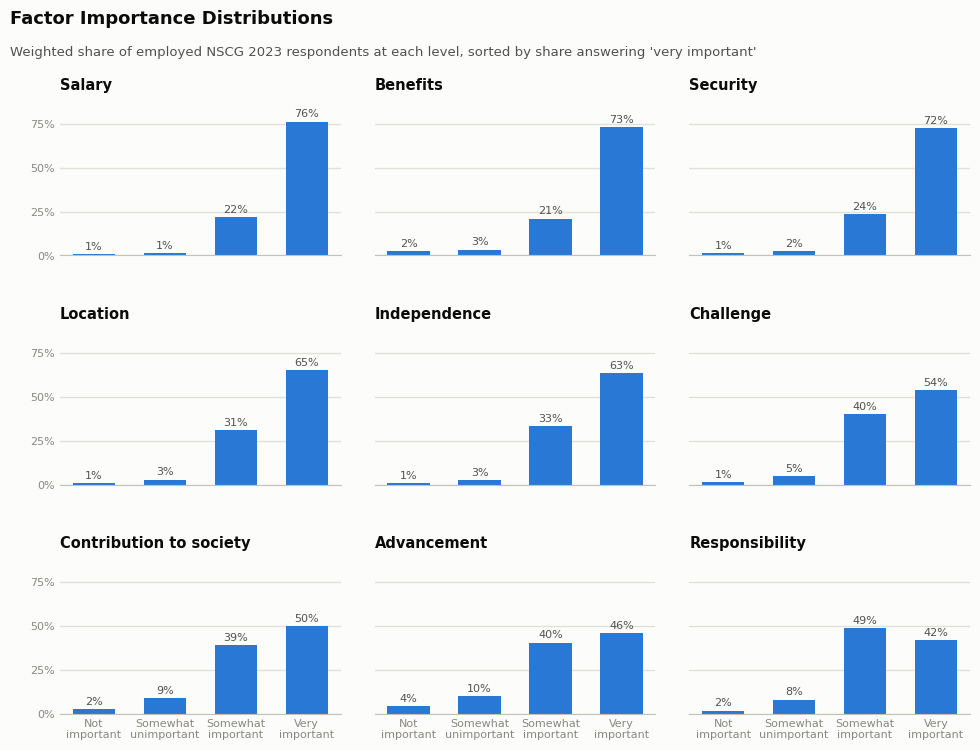

,Not important at all,Somewhat unimportant,Somewhat important,Very important
Salary,0.6,1.3,21.8,76.3
Benefits,2.3,3.3,21.0,73.3
Security,1.5,2.3,23.7,72.5
Location,1.0,2.8,31.1,65.1
Independence,0.6,2.6,33.3,63.5
Challenge,1.2,4.8,40.2,53.7
Contribution to society,2.4,8.8,38.9,49.9
Advancement,4.1,9.8,40.4,45.7
Responsibility,1.7,8.0,48.5,41.8


In [42]:
FACTOR_NAMES = {
    "ADV": "Advancement", "BEN": "Benefits", "CHAL": "Challenge", "IND": "Independence",
    "LOC": "Location", "RESP": "Responsibility", "SAL": "Salary", "SEC": "Security",
    "SOC": "Contribution to society",
}
# Reversed scale from cleaning: 1 = not important at all ... 4 = very important
LEVEL_TICKS = ["Not\nimportant", "Somewhat\nunimportant", "Somewhat\nimportant", "Very\nimportant"]
BAR = "#2a78d6"  # one series per panel, so one hue and no legend
SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

# Weighted % of respondents at each level, one row per factor
shares = pd.DataFrame(
    {FACTOR_NAMES[f]: df.groupby(f"FAC{f}").WTSURVY.sum() / df.WTSURVY.sum() * 100 for f in FACTORS}
).T.reindex(columns=[1, 2, 3, 4], fill_value=0)
shares = shares.sort_values(4, ascending=False)  # panels read from most to least "very important"

fig, axes = plt.subplots(3, 3, figsize=(10, 8), sharex=True, sharey=True, facecolor=SURFACE)
for ax, (name, row) in zip(axes.flat, shares.iterrows()):
    ax.set_facecolor(SURFACE)
    ax.bar(range(4), row.values, width=0.6, color=BAR, zorder=2)
    for x, v in enumerate(row.values):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", color=INK_2, fontsize=8)
    ax.set_title(name, loc="left", color=INK, fontsize=10.5, fontweight="semibold")
    ax.set_ylim(0, 90)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_yticks([0, 25, 50, 75])
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    ax.tick_params(length=0, colors=MUTED, labelsize=8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)

for ax in axes[-1]:
    ax.set_xticks(range(4))
    ax.set_xticklabels(LEVEL_TICKS, color=MUTED, fontsize=8)

fig.subplots_adjust(left=0.07, right=0.98, top=0.86, bottom=0.09, hspace=0.45, wspace=0.12)
fig.text(0.02, 0.97, "Factor Importance Distributions",
         color=INK, fontsize=13, fontweight="semibold", va="top")
fig.text(0.02, 0.925, "Weighted share of employed NSCG 2023 respondents at each level, sorted by share answering 'very important'",
         color=INK_2, fontsize=9.5, va="top")
plt.show()

# Same numbers as a table, for exact values
LEVELS = {1: "Not important at all", 2: "Somewhat unimportant", 3: "Somewhat important", 4: "Very important"}
shares.rename(columns=LEVELS).round(1)

**What this shows**

- **Ceiling effect.** Every factor is "important" to 86–98% of respondents, so whether someone rates a factor important at all says little about them.
- **The variation is in "very important".** It ranges from 76% for salary to 42% for responsibility. Salary, benefits and security are near-universal priorities; responsibility, advancement and contribution to society split respondents most.
- **Implication for fit features.** Because importance has so little spread, person-job fit will likely need to use "very important" vs not (or the full scale relative to each person's own average) rather than the raw 1–4 score.

## 8. Correlations among the importance items

Spearman rank correlations between the nine `FAC*` items and the target `very_satisfied`. Spearman suits these 1-4 ordered scales better than Pearson, since it only assumes the levels are ordered, not evenly spaced. Correlations are unweighted.

Only the lower triangle is shown, since the matrix is symmetric.

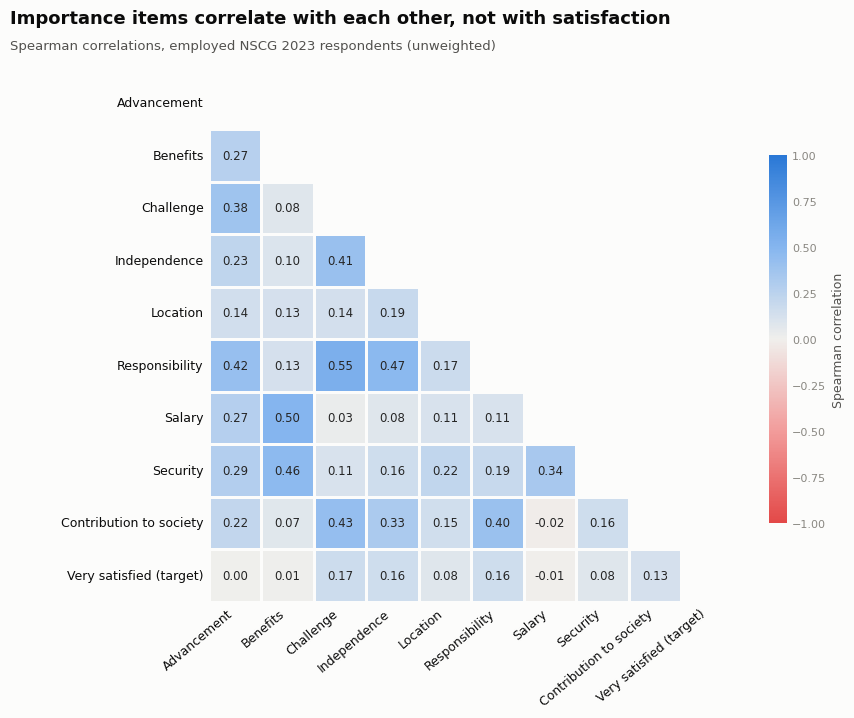

In [43]:
HEAT_COLS = FAC_COLS + ["very_satisfied"]
HEAT_NAMES = {f"FAC{f}": FACTOR_NAMES[f] for f in FACTORS} | {"very_satisfied": "Very satisfied (target)"}

corr = df[HEAT_COLS].corr(method="spearman").rename(index=HEAT_NAMES, columns=HEAT_NAMES)
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide the diagonal and the mirrored upper half

# Diverging: red (negative) <-> neutral gray at 0 <-> blue (positive)
DIVERGING = LinearSegmentedColormap.from_list(
    "red_gray_blue", ["#e34948", "#f29c9b", "#f0efec", "#86b6ef", "#2a78d6"]
)

fig, ax = plt.subplots(figsize=(9, 7.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
sns.heatmap(
    corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"fontsize": 8.5},
    linewidths=2, linecolor=SURFACE, square=True,
    cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax,
)
ax.tick_params(length=0, colors=INK, labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(length=0, colors=MUTED, labelsize=8)
cbar.outline.set_visible(False)
cbar.set_label("Spearman correlation", color=INK_2, fontsize=9)

fig.text(0.02, 0.97, "Importance items correlate with each other, not with satisfaction",
         color=INK, fontsize=13, fontweight="semibold", va="top")
fig.text(0.02, 0.93, "Spearman correlations, employed NSCG 2023 respondents (unweighted)",
         color=INK_2, fontsize=9.5, va="top")
fig.subplots_adjust(top=0.88, left=0.2, right=0.98, bottom=0.18)
plt.show()